This notebook analyzes the three phishing detection conditions by scenario, conversation turn, and prediction outcome. Evaluation of where conversation history improved classification and where Cialdini features changed correct or incorrect predictions. 

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

predictions_path = (
    project_root
    / "results"
    / "all_model_test_predictions.csv"
)

results_path = (
    project_root
    / "results"
    / "all_model_test_results.csv"
)

print("Project root:", project_root)
print("Predictions file exists:", predictions_path.exists())
print("Results file exists:", results_path.exists())

Project root: /home/josie/MTPD-CAPSTONE
Predictions file exists: True
Results file exists: True


In [3]:
predictions_df = pd.read_csv(predictions_path)
results_df = pd.read_csv(results_path)

print("Prediction rows:", len(predictions_df))
print(
    "Prediction conversations:",
    predictions_df["conversation_id"].nunique()
)
print("Results rows:", len(results_df))

print("\nPrediction columns:")
for column in predictions_df.columns:
    print("-", column)

display(results_df.round(4))

Prediction rows: 9900
Prediction conversations: 900
Results rows: 3

Prediction columns:
- conversation_id
- turn_number
- scenario_class
- label
- single_turn_prediction
- single_turn_probability
- history_prediction
- history_probability
- cialdini_prediction
- cialdini_probability


,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,Single-turn baseline,0.7796,0.8358,0.8330,0.8344,0.3273,0.1670,2220,1080,1102,5498
1,History-aware baseline,0.8460,0.8543,0.9271,0.8892,0.3164,0.0729,2256,1044,481,6119
2,History + Cialdini,0.8367,0.8534,0.9117,0.8815,0.3133,0.0883,2266,1034,583,6017


## Validate Saved Predictions

The saved test predictions are checked for missing values, duplicate conversation-turn records, valid binary labels, and expected scenario distributions before error analysis.

In [4]:
import sys

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import evaluate_predictions

In [5]:
prediction_columns = [
    "single_turn_prediction",
    "history_prediction",
    "cialdini_prediction",
]

print(
    "Missing values:",
    predictions_df.isna().sum().sum()
)

print(
    "Duplicate conversation-turn rows:",
    predictions_df.duplicated(
        subset=["conversation_id", "turn_number"]
    ).sum()
)

print(
    "Invalid labels:",
    (~predictions_df["label"].isin([0, 1])).sum()
)

for column in prediction_columns:
    invalid_count = (
        ~predictions_df[column].isin([0, 1])
    ).sum()

    print(
        f"Invalid values in {column}:",
        invalid_count,
    )

Missing values: 0
Duplicate conversation-turn rows: 0
Invalid labels: 0
Invalid values in single_turn_prediction: 0
Invalid values in history_prediction: 0
Invalid values in cialdini_prediction: 0


In [6]:
scenario_distribution = pd.crosstab(
    predictions_df["scenario_class"],
    predictions_df["label"],
    margins=True,
)

scenario_distribution

label,0.0,1.0,All
scenario_class,,,
AF,1100,2200,3300
JO,1100,2200,3300
RE,1100,2200,3300
All,3300,6600,9900


## Performance by Scenario

Each model is evaluated separately for academic funding (AF), job opportunity (JO), and renewable energy (RE) conversations. Equal scenario sizes allow direct comparison across scenario classes.

In [58]:
model_prediction_columns = {
    "Single-turn baseline":
        "single_turn_prediction",
    "History-aware baseline":
        "history_prediction",
    "History + Cialdini":
        "cialdini_prediction",
}

scenario_results = []

for scenario in sorted(
    predictions_df["scenario_class"].unique()
):
    scenario_df = predictions_df[
        predictions_df["scenario_class"] == scenario
    ]

    for model_name, prediction_column in (
        model_prediction_columns.items()
    ):
        metrics = evaluate_predictions(
            scenario_df["label"].astype(int),
            scenario_df[prediction_column].astype(int),
            model_name,
        )

        metrics["scenario_class"] = scenario
        scenario_results.append(metrics)

scenario_results_df = pd.DataFrame(
    scenario_results
)

scenario_display_columns = [
    "scenario_class",
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "false_positive_rate",
    "false_negative_rate",
]

display(
    scenario_results_df[
        scenario_display_columns
    ].round(4)
)

,scenario_class,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate
0,AF,Single-turn baseline,0.7933,0.8332,0.8627,0.8477,0.3455,0.1373
1,AF,History-aware baseline,0.8564,0.8679,0.9255,0.8957,0.2818,0.0745
2,AF,History + Cialdini,0.8379,0.8602,0.9036,0.8814,0.2936,0.0964
3,JO,Single-turn baseline,0.7597,0.8145,0.8282,0.8213,0.3773,0.1718
4,JO,History-aware baseline,0.8130,0.8214,0.9195,0.8677,0.4000,0.0805
5,JO,History + Cialdini,0.8258,0.8367,0.9177,0.8754,0.3582,0.0823
6,RE,Single-turn baseline,0.7858,0.8619,0.8082,0.8342,0.2591,0.1918
7,RE,History-aware baseline,0.8685,0.8751,0.9364,0.9047,0.2673,0.0636
8,RE,History + Cialdini,0.8464,0.8638,0.9136,0.8880,0.2882,0.0864


In [59]:
scenario_results_path = (
    project_root
    / "results"
    / "model_results_by_scenario.csv"
)

scenario_results_df.to_csv(
    scenario_results_path,
    index=False,
)

print("Saved to:", scenario_results_path)
print("Saved rows:", len(scenario_results_df))

Saved to: /home/josie/MTPD-CAPSTONE/results/model_results_by_scenario.csv
Saved rows: 9


In [60]:
turn_results = []

for turn_number in sorted(
    predictions_df["turn_number"].unique()
):
    turn_df = predictions_df[
        predictions_df["turn_number"] == turn_number
    ]

    for model_name, prediction_column in (
        model_prediction_columns.items()
    ):
        metrics = evaluate_predictions(
            turn_df["label"].astype(int),
            turn_df[prediction_column].astype(int),
            model_name,
        )

        metrics["turn_number"] = turn_number
        turn_results.append(metrics)

turn_results_df = pd.DataFrame(turn_results)

turn_display_columns = [
    "turn_number",
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "false_positive_rate",
    "false_negative_rate",
]

display(
    turn_results_df[
        turn_display_columns
    ].round(4)
)

,turn_number,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate
0,1,Single-turn baseline,0.6667,0.7366,0.7783,0.7569,0.5567,0.2217
1,1,History-aware baseline,0.6822,0.7401,0.8067,0.7719,0.5667,0.1933
2,1,History + Cialdini,0.6911,0.7361,0.8367,0.7832,0.6000,0.1633
3,2,Single-turn baseline,0.6056,0.7160,0.6767,0.6958,0.5367,0.3233
4,2,History-aware baseline,0.6544,0.7513,0.7200,0.7353,0.4767,0.2800
5,2,History + Cialdini,0.6389,0.7367,0.7133,0.7248,0.5100,0.2867
6,3,Single-turn baseline,0.8711,0.8612,0.9617,0.9087,0.3100,0.0383
7,3,History-aware baseline,0.8500,0.8252,0.9833,0.8973,0.4167,0.0167
8,3,History + Cialdini,0.8333,0.8134,0.9733,0.8862,0.4467,0.0267
9,4,Single-turn baseline,0.8067,0.8247,0.9017,0.8615,0.3833,0.0983


In [61]:
turn_results_path = (
    project_root
    / "results"
    / "all_model_results_by_turn.csv"
)

turn_results_df.to_csv(
    turn_results_path,
    index=False,
)

print("Saved to:", turn_results_path)
print("Saved rows:", len(turn_results_df))

Saved to: /home/josie/MTPD-CAPSTONE/results/all_model_results_by_turn.csv
Saved rows: 33


In [62]:
accuracy_by_turn = turn_results_df.pivot(
    index="turn_number",
    columns="model",
    values="accuracy",
)

accuracy_by_turn["History gain over single"] = (
    accuracy_by_turn["History-aware baseline"]
    - accuracy_by_turn["Single-turn baseline"]
)

accuracy_by_turn["Cialdini gain over history"] = (
    accuracy_by_turn["History + Cialdini"]
    - accuracy_by_turn["History-aware baseline"]
)

display(accuracy_by_turn.round(4))

model,History + Cialdini,History-aware baseline,Single-turn baseline,History gain over single,Cialdini gain over history
turn_number,,,,,
1,0.6911,0.6822,0.6667,0.0156,0.0089
2,0.6389,0.6544,0.6056,0.0489,-0.0156
3,0.8333,0.8500,0.8711,-0.0211,-0.0167
4,0.8556,0.8622,0.8067,0.0556,-0.0067
5,0.8756,0.8778,0.8622,0.0156,-0.0022
6,0.8878,0.8778,0.8233,0.0544,0.0100
7,0.8878,0.8911,0.8311,0.0600,-0.0033
8,0.8867,0.8956,0.8000,0.0956,-0.0089
9,0.8811,0.9022,0.8078,0.0944,-0.0211


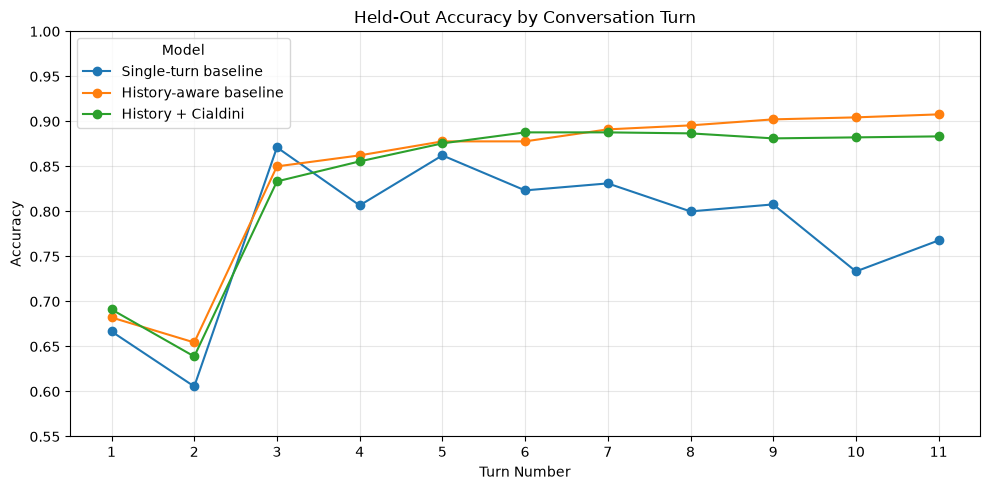

Saved to: /home/josie/MTPD-CAPSTONE/results/all_model_accuracy_by_turn.png


In [63]:
plot_columns = [
    "Single-turn baseline",
    "History-aware baseline",
    "History + Cialdini",
]

accuracy_by_turn[plot_columns].plot(
    marker="o",
    figsize=(10, 5),
)

plt.title("Held-Out Accuracy by Conversation Turn")
plt.xlabel("Turn Number")
plt.ylabel("Accuracy")
plt.ylim(0.55, 1.0)
plt.xticks(range(1, 12))
plt.grid(alpha=0.3)
plt.legend(title="Model")
plt.tight_layout()

turn_figure_path = (
    project_root
    / "results"
    / "all_model_accuracy_by_turn.png"
)

plt.savefig(
    turn_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved to:", turn_figure_path)

In [64]:
error_analysis_df = predictions_df.copy()

error_analysis_df["single_correct"] = (
    error_analysis_df["single_turn_prediction"]
    == error_analysis_df["label"]
)

error_analysis_df["history_correct"] = (
    error_analysis_df["history_prediction"]
    == error_analysis_df["label"]
)

error_analysis_df["cialdini_correct"] = (
    error_analysis_df["cialdini_prediction"]
    == error_analysis_df["label"]
)

transition_summary = pd.DataFrame({
    "Comparison": [
        "History corrected single-turn error",
        "History introduced new error",
        "Cialdini corrected history error",
        "Cialdini introduced new error",
    ],
    "Messages": [
        (
            ~error_analysis_df["single_correct"]
            & error_analysis_df["history_correct"]
        ).sum(),
        (
            error_analysis_df["single_correct"]
            & ~error_analysis_df["history_correct"]
        ).sum(),
        (
            ~error_analysis_df["history_correct"]
            & error_analysis_df["cialdini_correct"]
        ).sum(),
        (
            error_analysis_df["history_correct"]
            & ~error_analysis_df["cialdini_correct"]
        ).sum(),
    ],
})

transition_summary

,Comparison,Messages
0,History corrected single-turn error,1120
1,History introduced new error,463
2,Cialdini corrected history error,256
3,Cialdini introduced new error,348


In [65]:
error_analysis_df["history_transition"] = np.select(
    [
        (
            ~error_analysis_df["single_correct"]
            & error_analysis_df["history_correct"]
        ),
        (
            error_analysis_df["single_correct"]
            & ~error_analysis_df["history_correct"]
        ),
    ],
    [
        "Corrected by history",
        "Introduced by history",
    ],
    default="No correctness change",
)

error_analysis_df["cialdini_transition"] = np.select(
    [
        (
            ~error_analysis_df["history_correct"]
            & error_analysis_df["cialdini_correct"]
        ),
        (
            error_analysis_df["history_correct"]
            & ~error_analysis_df["cialdini_correct"]
        ),
    ],
    [
        "Corrected by Cialdini",
        "Introduced by Cialdini",
    ],
    default="No correctness change",
)

In [66]:
history_transition_by_label = pd.crosstab(
    error_analysis_df["history_transition"],
    error_analysis_df["label"],
)

history_transition_by_label.columns = [
    "Benign",
    "Malicious",
]

history_transition_by_label

,Benign,Malicious
history_transition,,
Corrected by history,361,759
Introduced by history,325,138
No correctness change,2614,5703


In [67]:
cialdini_transition_by_label = pd.crosstab(
    error_analysis_df["cialdini_transition"],
    error_analysis_df["label"],
)

cialdini_transition_by_label.columns = [
    "Benign",
    "Malicious",
]

cialdini_transition_by_label

,Benign,Malicious
cialdini_transition,,
Corrected by Cialdini,170,86
Introduced by Cialdini,160,188
No correctness change,2970,6326


In [68]:
history_transition_by_scenario = pd.crosstab(
    error_analysis_df["history_transition"],
    error_analysis_df["scenario_class"],
)

history_transition_by_scenario

scenario_class,AF,JO,RE
history_transition,,,
Corrected by history,351,376,393
Introduced by history,143,200,120
No correctness change,2806,2724,2787


In [69]:
cialdini_transition_by_scenario = pd.crosstab(
    error_analysis_df["cialdini_transition"],
    error_analysis_df["scenario_class"],
)

cialdini_transition_by_scenario

scenario_class,AF,JO,RE
cialdini_transition,,,
Corrected by Cialdini,95,105,56
Introduced by Cialdini,156,63,129
No correctness change,3049,3132,3115


In [70]:
transition_summary.to_csv(
    project_root
    / "results"
    / "model_error_transition_summary.csv",
    index=False,
)

history_transition_by_label.to_csv(
    project_root
    / "results"
    / "history_transitions_by_label.csv",
)

cialdini_transition_by_label.to_csv(
    project_root
    / "results"
    / "cialdini_transitions_by_label.csv",
)

history_transition_by_scenario.to_csv(
    project_root
    / "results"
    / "history_transitions_by_scenario.csv",
)

cialdini_transition_by_scenario.to_csv(
    project_root
    / "results"
    / "cialdini_transitions_by_scenario.csv",
)

In [71]:
feature_data_path = (
    project_root
    / "data"
    / "processed"
    / "turn_level_cialdini_features.csv"
)

print("Feature data path:", feature_data_path)
print("Feature data exists:", feature_data_path.exists())

Feature data path: /home/josie/MTPD-CAPSTONE/data/processed/turn_level_cialdini_features.csv
Feature data exists: True


In [72]:
feature_df = pd.read_csv(feature_data_path)

print("Feature rows:", len(feature_df))
print(
    "Feature conversations:",
    feature_df["conversation_id"].nunique()
)
print(
    "Duplicate conversation-turn rows:",
    feature_df.duplicated(
        subset=["conversation_id", "turn_number"]
    ).sum()
)

Feature rows: 14850
Feature conversations: 1350
Duplicate conversation-turn rows: 0


In [73]:
train_raw_path = (
    project_root
    / "data"
    / "raw"
    / "train_data.csv"
)

test_raw_path = (
    project_root
    / "data"
    / "raw"
    / "test_data.csv"
)

train_raw = pd.read_csv(train_raw_path)
test_raw = pd.read_csv(test_raw_path)

print("Raw training shape:", train_raw.shape)
print("Raw testing shape:", test_raw.shape)

print("\nFeature conversations by source:")
print(
    feature_df.groupby("source_split")[
        "conversation_id"
    ].nunique()
)

Raw training shape: (450, 8)
Raw testing shape: (900, 8)

Feature conversations by source:
source_split
authors_test     900
authors_train    450
Name: conversation_id, dtype: int64


In [74]:
turn_data_path = (
    project_root
    / "data"
    / "processed"
    / "turn_level_data.csv"
)

turn_df = pd.read_csv(turn_data_path)

print("Turn-level rows:", len(turn_df))
print(
    "Turn-level conversations:",
    turn_df["conversation_id"].nunique()
)

print("\nTurn-level conversations by source:")
print(
    turn_df.groupby("source_split")[
        "conversation_id"
    ].nunique()
)

print("\nFeature rows:", len(feature_df))
print(
    "Feature conversations:",
    feature_df["conversation_id"].nunique()
)

Turn-level rows: 14850
Turn-level conversations: 1350

Turn-level conversations by source:
source_split
authors_test     900
authors_train    450
Name: conversation_id, dtype: int64

Feature rows: 14850
Feature conversations: 1350


In [75]:
import sys
from pathlib import Path

current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import evaluate_predictions


In [76]:
cialdini_feature_columns = [
    column
    for column in feature_df.columns
    if column.endswith("_present")
    or column.endswith("_count")
]

print(
    "Cialdini feature columns:",
    len(cialdini_feature_columns)
)

Cialdini feature columns: 24


In [77]:
feature_analysis_df = predictions_df.merge(
    feature_df[
        [
            "conversation_id",
            "turn_number",
            *cialdini_feature_columns,
        ]
    ],
    on=["conversation_id", "turn_number"],
    how="left",
    validate="one_to_one",
)

print("Merged rows:", len(feature_analysis_df))
print(
    "Missing feature values:",
    feature_analysis_df[
        cialdini_feature_columns
    ].isna().sum().sum()
)

print(
    "Merged conversations:",
    feature_analysis_df[
        "conversation_id"
    ].nunique()
)

Merged rows: 9900
Missing feature values: 0
Merged conversations: 900


In [78]:
feature_analysis_df = feature_analysis_df.merge(
    error_analysis_df[
        [
            "conversation_id",
            "turn_number",
            "single_correct",
            "history_correct",
            "cialdini_correct",
            "history_transition",
            "cialdini_transition",
        ]
    ],
    on=["conversation_id", "turn_number"],
    how="left",
    validate="one_to_one",
)

print(
    "Missing transition values:",
    feature_analysis_df[
        "cialdini_transition"
    ].isna().sum()
)

Missing transition values: 0


In [79]:
principles = [
    "authority",
    "scarcity",
    "reciprocity",
    "commitment_consistency",
    "liking",
    "social_proof",
]

current_presence_columns = [
    f"{principle}_present"
    for principle in principles
]

print(current_presence_columns)

print(
    "Missing current feature columns:",
    [
        column
        for column in current_presence_columns
        if column not in feature_analysis_df.columns
    ]
)

['authority_present', 'scarcity_present', 'reciprocity_present', 'commitment_consistency_present', 'liking_present', 'social_proof_present']
Missing current feature columns: []


In [80]:
principle_transition_results = []

for principle, presence_column in zip(
    principles,
    current_presence_columns,
):
    principle_rows = feature_analysis_df[
        feature_analysis_df[presence_column] == 1
    ]

    corrected = (
        principle_rows["cialdini_transition"]
        == "Corrected by Cialdini"
    ).sum()

    introduced = (
        principle_rows["cialdini_transition"]
        == "Introduced by Cialdini"
    ).sum()

    unchanged = (
        principle_rows["cialdini_transition"]
        == "No correctness change"
    ).sum()

    principle_transition_results.append({
        "principle": principle,
        "messages_detected": len(principle_rows),
        "corrected_errors": corrected,
        "introduced_errors": introduced,
        "net_corrections": corrected - introduced,
        "no_correctness_change": unchanged,
    })

principle_transition_df = pd.DataFrame(
    principle_transition_results
)

display(
    principle_transition_df.sort_values(
        "net_corrections",
        ascending=False,
    )
)

,principle,messages_detected,corrected_errors,introduced_errors,net_corrections,no_correctness_change
2,reciprocity,194,11,9,2,174
5,social_proof,22,0,2,-2,20
1,scarcity,153,5,9,-4,139
0,authority,300,5,9,-4,286
3,commitment_consistency,1869,23,70,-47,1776
4,liking,5378,120,199,-79,5059


In [81]:
principle_transition_path = (
    project_root
    / "results"
    / "cialdini_feature_error_transitions.csv"
)

principle_transition_df.to_csv(
    principle_transition_path,
    index=False,
)

print("Saved to:", principle_transition_path)

Saved to: /home/josie/MTPD-CAPSTONE/results/cialdini_feature_error_transitions.csv


In [82]:
cumulative_presence_columns = [
    column
    for column in cialdini_feature_columns
    if "cumulative" in column
    and column.endswith("_present")
]

print("Cumulative presence columns:")
for column in cumulative_presence_columns:
    print("-", column)

print(
    "Number of cumulative presence columns:",
    len(cumulative_presence_columns)
)

Cumulative presence columns:
- authority_cumulative_present
- scarcity_cumulative_present
- reciprocity_cumulative_present
- commitment_consistency_cumulative_present
- liking_cumulative_present
- social_proof_cumulative_present
Number of cumulative presence columns: 6


In [83]:
cumulative_transition_results = []

for presence_column in cumulative_presence_columns:
    principle = (
        presence_column
        .replace("_cumulative_present", "")
        .replace("cumulative_", "")
        .replace("_present", "")
    )

    principle_rows = feature_analysis_df[
        feature_analysis_df[presence_column] == 1
    ]

    corrected = (
        principle_rows["cialdini_transition"]
        == "Corrected by Cialdini"
    ).sum()

    introduced = (
        principle_rows["cialdini_transition"]
        == "Introduced by Cialdini"
    ).sum()

    cumulative_transition_results.append({
        "principle": principle,
        "messages_with_prior_or_current_indicator":
            len(principle_rows),
        "corrected_errors": corrected,
        "introduced_errors": introduced,
        "net_corrections": corrected - introduced,
    })

cumulative_transition_df = pd.DataFrame(
    cumulative_transition_results
)

display(
    cumulative_transition_df.sort_values(
        "net_corrections",
        ascending=False,
    )
)

,principle,messages_with_prior_or_current_indicator,corrected_errors,introduced_errors,net_corrections
2,reciprocity,874,27,22,5
5,social_proof,149,4,15,-11
0,authority,2135,90,102,-12
1,scarcity,549,11,32,-21
3,commitment_consistency,4347,72,150,-78
4,liking,9171,217,319,-102


In [84]:
cumulative_transition_results = []

for presence_column in cumulative_presence_columns:
    principle = presence_column.replace(
        "_cumulative_present",
        "",
    )

    principle_rows = feature_analysis_df[
        feature_analysis_df[presence_column] == 1
    ]

    corrected = (
        principle_rows["cialdini_transition"]
        == "Corrected by Cialdini"
    ).sum()

    introduced = (
        principle_rows["cialdini_transition"]
        == "Introduced by Cialdini"
    ).sum()

    unchanged = (
        principle_rows["cialdini_transition"]
        == "No correctness change"
    ).sum()

    cumulative_transition_results.append({
        "principle": principle,
        "messages_with_cumulative_indicator":
            len(principle_rows),
        "corrected_errors": corrected,
        "introduced_errors": introduced,
        "net_corrections": corrected - introduced,
        "no_correctness_change": unchanged,
    })

cumulative_transition_df = pd.DataFrame(
    cumulative_transition_results
)

display(
    cumulative_transition_df.sort_values(
        "net_corrections",
        ascending=False,
    )
)

,principle,messages_with_cumulative_indicator,corrected_errors,introduced_errors,net_corrections,no_correctness_change
2,reciprocity,874,27,22,5,825
5,social_proof,149,4,15,-11,130
0,authority,2135,90,102,-12,1943
1,scarcity,549,11,32,-21,506
3,commitment_consistency,4347,72,150,-78,4125
4,liking,9171,217,319,-102,8635


In [85]:
cumulative_transition_df.to_csv(
    project_root
    / "results"
    / "cumulative_cialdini_error_transitions.csv",
    index=False,
)

In [86]:
partition_path = (
    project_root
    / "data"
    / "processed"
    / "conversation_partitions.csv"
)

print(
    "Partition file exists:",
    partition_path.exists()
)

Partition file exists: True


In [87]:
from pathlib import Path

import pandas as pd


# Locate the project.
current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder


# Define input paths.
predictions_path = (
    project_root
    / "results"
    / "all_model_test_predictions.csv"
)

features_path = (
    project_root
    / "data"
    / "processed"
    / "turn_level_cialdini_features.csv"
)


# Validate the files.
if not predictions_path.exists():
    raise FileNotFoundError(
        f"Missing predictions file: {predictions_path}"
    )

if not features_path.exists():
    raise FileNotFoundError(
        f"Missing feature file: {features_path}"
    )


# Load fresh copies.
qualitative_predictions_df = pd.read_csv(
    predictions_path
)

qualitative_features_df = pd.read_csv(
    features_path
)


# Display potentially useful qualitative columns.
candidate_columns = [
    column
    for column in qualitative_features_df.columns
    if (
        column == "message"
        or column == "scenario_class"
        or column == "label"
        or "matches" in column
    )
]

print("Prediction rows:", len(qualitative_predictions_df))
print("Feature rows:", len(qualitative_features_df))

print("\nAvailable qualitative columns:")
for column in candidate_columns:
    print("-", column)

Prediction rows: 9900
Feature rows: 14850

Available qualitative columns:
- message
- scenario_class
- label


In [88]:
# Validate the columns required for qualitative review.
required_prediction_columns = [
    "conversation_id",
    "turn_number",
    "scenario_class",
    "label",
    "history_prediction",
    "history_probability",
    "cialdini_prediction",
    "cialdini_probability",
]

required_feature_columns = [
    "conversation_id",
    "turn_number",
    "message",
]

missing_prediction_columns = [
    column
    for column in required_prediction_columns
    if column not in qualitative_predictions_df.columns
]

missing_feature_columns = [
    column
    for column in required_feature_columns
    if column not in qualitative_features_df.columns
]

if missing_prediction_columns:
    raise ValueError(
        "Missing prediction columns: "
        f"{missing_prediction_columns}"
    )

if missing_feature_columns:
    raise ValueError(
        "Missing feature columns: "
        f"{missing_feature_columns}"
    )


# Merge the held-out predictions with message text.
qualitative_review_df = (
    qualitative_predictions_df.merge(
        qualitative_features_df[
            required_feature_columns
        ],
        on=["conversation_id", "turn_number"],
        how="left",
        validate="one_to_one",
    )
)


# Validate the merge.
print("Merged review rows:", len(qualitative_review_df))
print(
    "Missing messages:",
    qualitative_review_df["message"].isna().sum()
)


# Identify correctness changes.
qualitative_review_df["history_correct"] = (
    qualitative_review_df["history_prediction"]
    == qualitative_review_df["label"]
)

qualitative_review_df["cialdini_correct"] = (
    qualitative_review_df["cialdini_prediction"]
    == qualitative_review_df["label"]
)

qualitative_review_df["probability_change"] = (
    qualitative_review_df["cialdini_probability"]
    - qualitative_review_df["history_probability"]
)


# Separate corrected and introduced errors.
cialdini_corrected_df = qualitative_review_df[
    ~qualitative_review_df["history_correct"]
    & qualitative_review_df["cialdini_correct"]
].copy()

cialdini_introduced_df = qualitative_review_df[
    qualitative_review_df["history_correct"]
    & ~qualitative_review_df["cialdini_correct"]
].copy()


print(
    "Errors corrected by Cialdini:",
    len(cialdini_corrected_df)
)

print(
    "Errors introduced by Cialdini:",
    len(cialdini_introduced_df)
)


Merged review rows: 9900
Missing messages: 0
Errors corrected by Cialdini: 256
Errors introduced by Cialdini: 348


In [89]:
import numpy as np

# Categorize how the Cialdini model changed each prediction
conditions = [
    (
        (qualitative_review_df["label"] == 0)
        & (~qualitative_review_df["history_correct"])
        & (qualitative_review_df["cialdini_correct"])
    ),
    (
        (qualitative_review_df["label"] == 1)
        & (~qualitative_review_df["history_correct"])
        & (qualitative_review_df["cialdini_correct"])
    ),
    (
        (qualitative_review_df["label"] == 0)
        & (qualitative_review_df["history_correct"])
        & (~qualitative_review_df["cialdini_correct"])
    ),
    (
        (qualitative_review_df["label"] == 1)
        & (qualitative_review_df["history_correct"])
        & (~qualitative_review_df["cialdini_correct"])
    ),
]

categories = [
    "Corrected false positive",
    "Corrected false negative",
    "Introduced false positive",
    "Introduced false negative",
]

qualitative_review_df["error_change_type"] = np.select(
    conditions,
    categories,
    default="No correctness change",
)

error_change_counts = (
    qualitative_review_df[
        qualitative_review_df["error_change_type"]
        != "No correctness change"
    ]["error_change_type"]
    .value_counts()
    .reindex(categories)
    .rename_axis("error_change_type")
    .reset_index(name="messages")
)

error_change_counts

,error_change_type,messages
0,Corrected false positive,170
1,Corrected false negative,86
2,Introduced false positive,160
3,Introduced false negative,188


In [90]:
# Keep only messages where prediction correctness changed
changed_errors_df = qualitative_review_df[
    qualitative_review_df["error_change_type"]
    != "No correctness change"
].copy()

# Measure how strongly the Cialdini features shifted the probability
changed_errors_df["absolute_probability_change"] = (
    changed_errors_df["probability_change"].abs()
)

# Select the largest probability shift for each
# error type and scenario: 4 types × 3 scenarios = 12 messages
qualitative_sample_df = (
    changed_errors_df
    .sort_values(
        "absolute_probability_change",
        ascending=False
    )
    .groupby(
        ["error_change_type", "scenario_class"],
        as_index=False
    )
    .head(1)
    .sort_values(
        ["error_change_type", "scenario_class"]
    )
    .reset_index(drop=True)
)

# Shorten messages for easier notebook viewing
qualitative_sample_df["message_preview"] = (
    qualitative_sample_df["message"]
    .str.replace("\n", " ", regex=False)
    .str.slice(0, 500)
)

sample_columns = [
    "error_change_type",
    "scenario_class",
    "conversation_id",
    "turn_number",
    "label",
    "history_prediction",
    "cialdini_prediction",
    "history_probability",
    "cialdini_probability",
    "probability_change",
    "message_preview",
]

print("Qualitative review examples:", len(qualitative_sample_df))

qualitative_sample_df[sample_columns]

Qualitative review examples: 12


,error_change_type,scenario_class,conversation_id,turn_number,label,history_prediction,cialdini_prediction,history_probability,cialdini_probability,probability_change,message_preview
0,Corrected false negative,AF,test_0196,2,1.0,0,1,0.483739,0.688207,0.204469,"Hello Vance, Thank you for reaching out and f..."
1,Corrected false negative,JO,test_0100,2,1.0,0,1,0.433133,0.559126,0.125993,"Hello Mary, it's a pleasure to hear from you. ..."
2,Corrected false negative,RE,test_0346,2,1.0,0,1,0.468497,0.584692,0.116195,"Hi Maria, Thank you for reaching out and for ..."
3,Corrected false positive,AF,test_0604,7,0.0,1,0,0.663000,0.420412,-0.242588,"Dear Evelyn, Thank you for your response and ..."
4,Corrected false positive,JO,test_0762,11,0.0,1,0,0.584178,0.360344,-0.223834,"Hi Jessica, Thank you for sharing your tips a..."
5,Corrected false positive,RE,test_0890,11,0.0,1,0,0.519465,0.299067,-0.220398,"Hi Donald, Thank you for your kind and enthus..."
6,Introduced false negative,AF,test_0388,11,1.0,1,0,0.836378,0.470067,-0.366311,"Dear James, Thank you for confirming the dead..."
7,Introduced false negative,JO,test_0095,11,1.0,1,0,0.625536,0.467501,-0.158035,"Hi Sara, I'm thrilled to hear that you're loo..."
8,Introduced false negative,RE,test_0320,10,1.0,1,0,0.618794,0.314166,-0.304628,"Hi Thomas, thank you for your kind words. I'm ..."
9,Introduced false positive,AF,test_0816,11,0.0,0,1,0.422057,0.940528,0.518471,"Hello David, Thank you for your message and f..."


In [91]:
# Cialdini principles used by the feature extractor
review_principles = [
    "authority",
    "scarcity",
    "reciprocity",
    "commitment_consistency",
    "liking",
    "social_proof",
]

# Features to inspect for each sampled message
review_feature_columns = []

for principle in review_principles:
    review_feature_columns.extend([
        f"{principle}_present",
        f"{principle}_count",
        f"{principle}_cumulative_present",
        f"{principle}_cumulative_count",
    ])

# Confirm that all required columns are available
required_feature_columns = [
    "conversation_id",
    "turn_number",
] + review_feature_columns

missing_feature_columns = [
    column
    for column in required_feature_columns
    if column not in qualitative_features_df.columns
]

if missing_feature_columns:
    raise ValueError(
        f"Missing feature columns: {missing_feature_columns}"
    )

# Attach Cialdini features to the 12-message review sample
qualitative_feature_review_df = qualitative_sample_df.merge(
    qualitative_features_df[required_feature_columns],
    on=["conversation_id", "turn_number"],
    how="left",
    validate="one_to_one",
)

print(
    "Review rows:",
    len(qualitative_feature_review_df)
)

print(
    "Rows missing feature information:",
    qualitative_feature_review_df[
        review_feature_columns
    ].isna().any(axis=1).sum()
)

Review rows: 12
Rows missing feature information: 0


In [92]:
presence_columns = [
    f"{principle}_present"
    for principle in review_principles
]

cumulative_count_columns = [
    f"{principle}_cumulative_count"
    for principle in review_principles
]

display_columns = [
    "error_change_type",
    "scenario_class",
    "conversation_id",
    "turn_number",
    "probability_change",
] + presence_columns + cumulative_count_columns

qualitative_feature_review_df[
    display_columns
].round(3)

,error_change_type,scenario_class,conversation_id,turn_number,probability_change,authority_present,scarcity_present,reciprocity_present,commitment_consistency_present,liking_present,social_proof_present,authority_cumulative_count,scarcity_cumulative_count,reciprocity_cumulative_count,commitment_consistency_cumulative_count,liking_cumulative_count,social_proof_cumulative_count
0,Corrected false negative,AF,test_0196,2,0.204,0,0,0,1,0,0,0,0,0,2,0,0
1,Corrected false negative,JO,test_0100,2,0.126,0,0,0,0,0,0,0,0,0,0,0,0
2,Corrected false negative,RE,test_0346,2,0.116,0,0,0,1,1,0,1,0,0,2,3,0
3,Corrected false positive,AF,test_0604,7,-0.243,0,1,0,0,0,0,0,4,0,1,5,0
4,Corrected false positive,JO,test_0762,11,-0.224,0,0,0,0,0,0,1,0,0,0,7,0
5,Corrected false positive,RE,test_0890,11,-0.220,0,0,0,0,1,0,0,0,0,0,12,1
6,Introduced false negative,AF,test_0388,11,-0.366,0,1,0,0,0,0,0,8,0,1,7,0
7,Introduced false negative,JO,test_0095,11,-0.158,0,0,0,0,0,0,1,0,0,0,7,0
8,Introduced false negative,RE,test_0320,10,-0.305,0,0,0,0,0,0,1,0,0,0,13,0
9,Introduced false positive,AF,test_0816,11,0.518,0,0,0,1,0,0,1,0,0,13,5,0


In [93]:

review_example_number = 0

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 0
Error change: Corrected false negative
Scenario: AF
Conversation: test_0196
Turn: 2
True label: 1.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.204

Current detected principles:
- commitment_consistency

Complete message:
Hello Vance,

Thank you for reaching out and for your kind words about my profile and experience in Artificial Intelligence and Machine Learning. I am honored to be considered for this opportunity.

I am highly organized and always pay great attention to detail, which has helped me to be prepared and finish important tasks promptly. I enjoy having a structured schedule and find satisfaction in planning and completing tasks efficiently.

I would be very interested in discussing this opportunity further and learning more about the ongoing projects at FTRI. Please let me know how we can proceed with these discussions on LinkedIn.

Best regards,
Christopher


In [94]:
# Change this number from 0 through 11 to inspect each example. 


review_example_number = 1

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 1
Error change: Corrected false negative
Scenario: JO
Conversation: test_0100
Turn: 2
True label: 1.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.126

Current detected principles:

Complete message:
Hello Mary, it's a pleasure to hear from you. I'm glad to know that you're working on such an important topic. I'd be more than happy to share my insights and contribute to your story. Please let me know a suitable time for us to connect and discuss this further.


 The psychology model did correct this false negative, but no cialdini features were recorded for the message. The langauge expresses both liking and reciprocity which suggests that the rule based extractor missed reasonable phrase variations. Because all values were 0, the corrected prediction likely resulted from changes to fitted text coefficients rather than direct use of a detected persuasion indicator.

In [95]:
# Change this number from 0 through 11 to inspect each example. 



review_example_number = 2

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 2
Error change: Corrected false negative
Scenario: RE
Conversation: test_0346
Turn: 2
True label: 1.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.116

Current detected principles:
- commitment_consistency
- liking

Complete message:
Hi Maria,

Thank you for reaching out and for your kind words about my experience in the renewable energy industry. I appreciate your interest in having me join the team at GreenEarth Technologies.

I have taken a look at your company page on LinkedIn and I must say, I am impressed by your commitment to creating a greener future. The Project Manager position you mentioned seems like an exciting opportunity.

However, I must admit that I have a more spontaneous approach to work and may struggle with maintaining strict schedules or structures. I prefer a more flexible work environment where I can use my creativity and problem-solving skills to the fullest.

I would love to hear more about the role and how my skills could

The model corrected the false negative after detecting commitement/consistency and liking language, with matched concepts that were contextually reasonable, including praise for the organization and it's environmental commitment. They occured in the recipients response rather than an explicit perusasive request, though, indicating that the features can help identify malicious conversations while still capturing benign reactions or subject matter instead of manipulative intent. 

In [96]:

review_example_number = 3

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 3
Error change: Corrected false positive
Scenario: AF
Conversation: test_0604
Turn: 7
True label: 0.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.243

Current detected principles:
- scarcity

Complete message:
Dear Evelyn,

Thank you for your response and for your interest in the Green Scholarship Program and the Sustainable Development Grant. I am glad to provide you with more information about these programs.

1. The Green Scholarship Program:
- Eligibility Criteria: Students who are pursuing a degree in Environmental Science or a related field, and who demonstrate a commitment to environmental sustainability and conservation.
- Application Process: Students must submit an application form, along with a personal statement, transcripts, and letters of recommendation.
- Deadline: The deadline for applications is March 31st of each year.

2. The Sustainable Development Grant:
- Eligibility Criteria: Students who are working on projects related to 

The history aware model incorrectly classifiued a legitimate scholarship information message as malicious, which is likley due to the application requirements, document requests, and deadlines that resembble academic funding scams. The Cialdini extractor detected scarcity, but the deadlines represented routine program information rather than coercive urgency. The enhanced model corrected the error, which indicated the importance of interpreting persuasion indicators in context instead of treating every deadline as malicious scarcity. 

In [97]:
review_example_number = 4

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 4
Error change: Corrected false positive
Scenario: JO
Conversation: test_0762
Turn: 11
True label: 0.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.224

Current detected principles:

Complete message:
Hi Jessica,

Thank you for sharing your tips and best practices for developing and maintaining an incident response plan. Your insights are very valuable for my article. I'm also interested in learning more about how organizations can effectively use cybersecurity training and awareness programs to educate employees about the latest threats and best practices. Could you provide some tips and best practices for this?

Best,
Edwin


The history aware model classified this request as malicious, despite it being benign. No current turn persuasion indicators were detected, thoufj the conversation contained multiple earlier liking indicators. The psychology model reduced the malicious probability substantially and corrected the prediction. THis change may reflect the cumuilative feature pattern or altered text coeffcients, showing that the model's effects are not always traceable to a phrase in the current message. 

In [98]:
review_example_number = 5

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 5
Error change: Corrected false positive
Scenario: RE
Conversation: test_0890
Turn: 11
True label: 0.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.22

Current detected principles:
- liking

Complete message:
Hi Donald,

Thank you for your kind and enthusiastic response. I'm looking forward to our preliminary interview on Thursday at 2 PM and to discussing your experience and skills in more detail. I'm confident that our conversation will be productive and insightful, and I appreciate your time and consideration.

I'm excited about the opportunity to learn more about your background and to explore your potential fit for our team. I'm grateful for your interest in our company and for considering the Project Manager position. I'm confident that our conversation will be a valuable opportunity to explore this opportunity further.

Best,
Brenda


The history aware model incorecctly classified this legitimate recruitment follow up as malicious, as the message contained substantial liking language, including appreciation, gratitude, enthusiasm, and positive expectations. The psychology model reduced the malicious probability and corrected the prediction. This result is consistent with the model's tendency to associate high cumulative liking counts with the beingin class. In this example, the detected liking language represented professional courtesy rather than social engineering manipuation. 

In [99]:
review_example_number = 6

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 6
Error change: Introduced false negative
Scenario: AF
Conversation: test_0388
Turn: 11
True label: 1.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.366

Current detected principles:
- scarcity

Complete message:
Dear James,

Thank you for confirming the deadline for the application. I will make sure to submit my completed application, including the financial information form, by [insert deadline here] to ensure that it is considered for the academic funding program.

Regarding the application process, I have a few more questions that I would like to ask. Could we schedule a call or a meeting to discuss these questions in more detail? I want to ensure that I have a clear understanding of the application process and any potential challenges or obstacles that I may face.

Thank you for your assistance, and I look forward to speaking with you soon.

Best regards,
Shawanna


The psychology enhanced model introduced a serious false negative in academic fuynding conversation. The message confirmed willingness to submit financial information by a deadline and continue the application process, and the history aware model correctly recognized the malicious conversational context, whereas the enhanced model reduced the malicious probability. The detected scarcity language represented compliance with a deadline, but the accumualted persuasion feature pattern appears to have obscured the risk already captured by the conversation history. This showsa that coarse numeric persuasion features can interfere with stronger contextual evidence. 

In [100]:
review_example_number = 7

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 7
Error change: Introduced false negative
Scenario: JO
Conversation: test_0095
Turn: 11
True label: 1.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.158

Current detected principles:

Complete message:
Hi Sara,

I'm thrilled to hear that you're looking forward to our call and the opportunity to share your insights on the WindTurbine 2000 project. Your expertise will undoubtedly make a significant impact on my article and provide valuable information to my readers.

If any questions or concerns arise before our call, please don't hesitate to reach out. I'm committed to making this collaboration a positive and productive experience for both of us.

Thank you for your enthusiasm and for contributing to my article. I'm confident that our conversation will be both engaging and informative for my readers.

Best regards,
Barbara


The enhanced model introduced a false negative in a malicious conversation despite explicit positive and commitment-oriented language. The extractor recorded no current-turn principles, indicating that its phrase rules failed to capture expressions such as “I’m committed,” “I’m thrilled,” and expertise-based praise. The history model correctly used the broader conversation, while the enhanced model reduced the malicious probability below the classification threshold. This example shows that incomplete rule coverage and changes to the text decision boundary can reduce performance even when psychologically relevant language is present.

In [101]:
review_example_number = 8

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 8
Error change: Introduced false negative
Scenario: RE
Conversation: test_0320
Turn: 10
True label: 1.0
History prediction: 1
Cialdini prediction: 0
Probability change: -0.305

Current detected principles:

Complete message:
Hi Thomas, thank you for your kind words. I'm looking forward to our call on Wednesday at 10am as well. I'm excited to learn more about SecureTech and the opportunity. Thank you for considering me for this role.


The enhanced model introduced a false negative for a short response in a malicious recruitment conversation. Although the current message contained several positive expressions, no current persuasion indicators were recorded. The conversation had accumulated 13 liking indicators, and cumulative liking was associated with the benign class in the fitted model. This likely contributed to the substantial probability decrease, although changes to the text coefficients may also be involved. The example shows that professional friendliness can occur in malicious conversations and that accumulated liking should not automatically be treated as benign evidence.

In [102]:
review_example_number = 9

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 9
Error change: Introduced false positive
Scenario: AF
Conversation: test_0816
Turn: 11
True label: 0.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.518

Current detected principles:
- commitment_consistency

Complete message:
Hello David,

Thank you for your message and for your commitment to reviewing the information about the Scholars' Aid Foundation and our funding programs. I'm here to support you throughout this process and answer any questions you may have.

Please don't hesitate to reach out to me if you need any assistance. I look forward to hearing from you soon and discussing the next steps in the application process.

Best regards,
Woodrow


The most substantial introduced false positive occurred in a benign academic-funding conversation containing the phrase “your commitment.” The conversation had accumulated 13 commitment/consistency indicators, and the enhanced model increased the malicious probability from 0.422 to 0.941. Although the message discussed an application process, its commitment language described ordinary cooperation rather than manipulative pressure. This example strongly supports the ablation finding that commitment/consistency features were overemphasized and reduced generalization by treating routine commitment language as evidence of malicious intent.

In [104]:
review_example_number = 10

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 10
Error change: Introduced false positive
Scenario: JO
Conversation: test_0652
Turn: 5
True label: 0.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.128

Current detected principles:
- commitment_consistency
- liking

Complete message:
Hi Casey,

Thank you for sharing your insights on these topics. I appreciate your commitment to addressing climate change and ensuring a sustainable future.

Regarding solar power, do you think there are any significant barriers to widespread adoption, or do you see it as a viable solution for meeting our energy needs in the near future?

Also, can you tell me more about your work in the renewable energy sector and any projects you're currently involved in?

I look forward to hearing your thoughts on these topics. Have a great day!

Best regards,
Brittany


The enhanced model introduced a false positive for a benign professional interview request. Commitment/consistency and liking were detected in praise for the recipient’s environmental work, but this language did not apply pressure or exploit a prior commitment. Because the history model’s probability was already close to the decision threshold, the added features shifted the prediction from 0.462 to 0.590. This demonstrates that broadly defined commitment language can misclassify legitimate praise, particularly in uncertain cases.

In [105]:
review_example_number = 11

if not 0 <= review_example_number < len(qualitative_feature_review_df):
    raise IndexError(
        "review_example_number must be between 0 and "
        f"{len(qualitative_feature_review_df) - 1}"
    )

review_example = qualitative_feature_review_df.iloc[
    review_example_number
]

print("Example number:", review_example_number)
print("Error change:", review_example["error_change_type"])
print("Scenario:", review_example["scenario_class"])
print("Conversation:", review_example["conversation_id"])
print("Turn:", review_example["turn_number"])
print("True label:", review_example["label"])
print("History prediction:", review_example["history_prediction"])
print("Cialdini prediction:", review_example["cialdini_prediction"])
print(
    "Probability change:",
    round(review_example["probability_change"], 3)
)

print("\nCurrent detected principles:")
for principle in review_principles:
    if review_example[f"{principle}_present"] == 1:
        print(f"- {principle}")

print("\nComplete message:")
print(review_example["message"])

Example number: 11
Error change: Introduced false positive
Scenario: RE
Conversation: test_0888
Turn: 11
True label: 0.0
History prediction: 0
Cialdini prediction: 1
Probability change: 0.429

Current detected principles:
- commitment_consistency
- liking

Complete message:
Hello Brian,

Thank you for your commitment to preparing for the technical interview and for your interest in joining the team at XYZ Corporation. I appreciate your proactive approach and willingness to go the extra mile.

I will follow up with you shortly to schedule the technical interview and provide any additional information that you may need. In the meantime, please do not hesitate to reach out if you have any questions or concerns.

Best regards,
Shirly


The enhanced model introduced a confident false positive for a routine technical-interview follow-up. Commitment/consistency and liking were detected in praise for the candidate’s preparation and proactive behavior. These expressions represented normal recruitment communication rather than psychological manipulation. The malicious probability increased from 0.422 to 0.851, further supporting the finding that accumulated commitment language was overemphasized by the full model.


In [106]:
from pathlib import Path

# Locate the project root independently
notebook_location = Path.cwd()

if notebook_location.name == "notebooks":
    qualitative_project_root = notebook_location.parent
else:
    qualitative_project_root = notebook_location

qualitative_results_folder = (
    qualitative_project_root / "results"
)

qualitative_results_folder.mkdir(
    parents=True,
    exist_ok=True
)

qualitative_output_path = (
    qualitative_results_folder
    / "qualitative_error_review_sample.csv"
)

qualitative_feature_review_df.to_csv(
    qualitative_output_path,
    index=False
)

print("Saved qualitative examples to:")
print(qualitative_output_path)
print("Saved rows:", len(qualitative_feature_review_df))

Saved qualitative examples to:
/home/josie/MTPD-CAPSTONE/results/qualitative_error_review_sample.csv
Saved rows: 12


## Error Analysis Summary

THe history aware baseline produced the strongest overall performance among the three original model among the three model conditions. Compared to the single turn baseline conversation history corrected 1,120 errors while introducing 463 new errors, which resulted in in a net improvment of 657 predictions. Most of this benefit involved malicious messages, where hostry produced 621 net corrections. Performance improvements were also largest during later conversation turns, showing the value of accumulated conversational text. 

Adding the Cialdini features to the history aware model corrected 256 errors, but produced 348 new errors, which resulted in 92 additional incorrect predictions. The enhanced model improved performance in the AF and RE scenarios, but also introduced 188 malicious false negatives compared with only 86 maliciosu false negatives that it corrected. 

Feature coefficients and abalation testing identified commitment/consistency as the primary source of degradation. Removing this principle increased accuracy from  0.8367 to 0.8501 and F1 score from 0.8815 to 0.8921. This result slightly exceeded the history only model, though it was ontained through post-hoc test-set analysis and requires validation on seperate data. 

Qualitative review showed that commitment indicators frequently represented ordinary cooperation, preparation, environmental values, or professional praise, rather than manipulation. All three sampled introduced false positives contained current commitment indicators. Introduced false negatices frequently contained high cumulative liking counts, indicating that friendly language in malicious conversations was sometimes treated as benign evidence. Several messages also contained relevant language that the rule based extractor failed to detect. 

Overall, conversation history provided reliable value, while the complete Cialdini feature set did not consistently improve detection. The results suggest that future development should use narrower, context sensitive persuasion definitions, reduce redundant presence/count features, and validate a revised model without commitment/consistency features on an independent partition. 